In [1]:
import pandas as pd
import numpy as np

import re

import matplotlib.pyplot as plt
import seaborn as sns

import tensorflow as tf

In [2]:
from tensorflow.keras.preprocessing.text import Tokenizer
from tensorflow.keras.preprocessing.sequence import pad_sequences

from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Embedding, LSTM, Dense, Dropout, Bidirectional

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, classification_report, confusion_matrix

from collections import Counter

In [3]:
pd.set_option("display.max_columns", None)
pd.set_option("display.max_colwidth", None)

In [4]:
df = pd.read_csv("tweet_emotions.csv")
df.head()

,tweet_id,sentiment,content
0,1956967341,empty,@tiffanylue i know i was listenin to bad habit earlier and i started freakin at his part =[
1,1956967666,sadness,Layin n bed with a headache ughhhh...waitin on your call...
2,1956967696,sadness,Funeral ceremony...gloomy friday...
3,1956967789,enthusiasm,wants to hang out with friends SOON!
4,1956968416,neutral,"@dannycastillo We want to trade with someone who has Houston tickets, but no one will."


In [35]:
#Create a dictionary to map the the sentiment column 
emotion_mapping ={"neutral" : "neutral",
                 "worry": "sadness",
                "hate": "sadness",
                 "sadness": "sadness",
                 "happiness":"happiness",
                 "fun":"happiness",
                 "love":"love",
                 "relief":"love",
                 "enthusiasm":"love",
                 "surprise":"surprise",
                 "boredom":"surprise",
                 "empty": "surprise"}

In [36]:
df["new_sentiment"] = df["sentiment"].map(emotion_mapping)
df.head(50)

,tweet_id,sentiment,content,new_sentiment,clean_text,label
0,1956967341,empty,@tiffanylue i know i was listenin to bad habit earlier and i started freakin at his part =[,surprise,i know i was listenin to bad habit earlier and i started freakin at his part =[,4
1,1956967666,sadness,Layin n bed with a headache ughhhh...waitin on your call...,sadness,layin n bed with a headache ughhhh...waitin on your call...,3
2,1956967696,sadness,Funeral ceremony...gloomy friday...,sadness,funeral ceremony...gloomy friday...,3
3,1956967789,enthusiasm,wants to hang out with friends SOON!,love,wants to hang out with friends soon!,1
4,1956968416,neutral,"@dannycastillo We want to trade with someone who has Houston tickets, but no one will.",neutral,"we want to trade with someone who has houston tickets, but no one will.",2
5,1956968477,worry,Re-pinging @ghostridah14: why didn't you go to prom? BC my bf didn't like my friends,sadness,re-pinging : why didn't you go to prom? bc my bf didn't like my friends,3
6,1956968487,sadness,"I should be sleep, but im not! thinking about an old friend who I want. but he's married now. damn, &amp; he wants me 2! scandalous!",sadness,"i should be sleep, but im not! thinking about an old friend who i want. but he's married now. damn, &amp; he wants me 2! scandalous!",3
7,1956968636,worry,Hmmm. http://www.djhero.com/ is down,sadness,hmmm. is down,3
8,1956969035,sadness,@charviray Charlene my love. I miss you,sadness,charlene my love. i miss you,3
9,1956969172,sadness,@kelcouch I'm sorry at least it's Friday?,sadness,i'm sorry at least it's friday?,3


In [37]:
df["new_sentiment"].value_counts()

new_sentiment
sadness      14947
neutral       8638
happiness     6985
love          6127
surprise      3193
Name: count, dtype: int64

In [38]:
def clean_tweet(text):

    text = str(text)

    text = text.lower()

    text = re.sub(r"http\S+|www\s+","<URL>",text)

    text = re.sub(r"@\w+", " <USER> ", text)

    text = re.sub(r"<.*?>", " ", text)

    text = re.sub(r"\s+", " ", text)

    text = text.strip()

    return text

In [39]:
df["clean_text"] = df["content"].apply(clean_tweet)

In [40]:
df["clean_text"] = df["content"].apply(clean_tweet)

In [41]:
#using the lable encoder
label_encoder = LabelEncoder()
df["label"] = label_encoder.fit_transform(df["new_sentiment"])

In [42]:
for number, emotion in enumerate(label_encoder.classes_):
    print(number, "=", emotion)

0 = happiness
1 = love
2 = neutral
3 = sadness
4 = surprise
5 = nan


In [43]:
x = df["clean_text"]
y = df["label"]


In [44]:
#split dataset into 3 parts, training, validation and test part
x_train,x_test,y_train, y_test = train_test_split(x,y,test_size=0.3, random_state = 42, stratify = y)
# stratify ensures that that in both the training and test set there is the same proportion of the label
#validation set form the trainnig set 
x_train ,x_val, y_train, y_val = train_test_split(x_train,y_train,test_size = 0.2, random_state = 42, stratify = y_train)

In [45]:
max_words = 20000
tokenizer = Tokenizer(num_words = max_words,oov_token = "<OOV>")
tokenizer.fit_on_texts(x_train)

In [46]:
word_index = tokenizer.word_index
print(f"Vocab_size: {len(word_index)}")

Vocab_size: 22260


In [47]:
# reconstructs the tweets using these ids 
x_train_seq = tokenizer.texts_to_sequences(x_train)
x_val_seq = tokenizer.texts_to_sequences(x_val)
x_test_seq = tokenizer.texts_to_sequences(x_test)

In [48]:
sequence_lengths = [len(sequence) for sequence in x_train_seq]
print(pd.Series(sequence_lengths).describe())

count    22400.000000
mean        12.786295
std          7.050810
min          0.000000
25%          7.000000
50%         12.000000
75%         18.000000
max         36.000000
dtype: float64


In [49]:
# need to part the paragrapahs as it all has to all be the same size for the model to assert the data and actualy process the data for LSTM 
# Padding is going to cut off the tweets that are greater than the size set 
# truncating is going to cut tweets down to the right size ending up cuting of meaningful parts of the sentences
max_sequence = 40
x_train = pad_sequences(x_train_seq,maxlen = max_sequence, padding = "post", truncating = "post")
x_val = pad_sequences(x_val_seq,maxlen = max_sequence, padding = "post", truncating = "post") 
x_test = pad_sequences(x_test_seq,maxlen = max_sequence, padding = "post", truncating = "post") 

In [50]:
# build the LSTM
# explain each layer 
# tells us that the layers will be in a sequence or one after each other 
# multiple layers that perform different tasks
# first layer is the embedding
# converts what we generated from the tokeniser into a dense vector which carry more meaning 


model = Sequential()

# embedding layer with 2 params 
model.add(Embedding(input_dim = max_words, output_dim = 128)) # dimention is going to be 20000 to 128 


# LSTM LAYER 
# LSTM processes the sequence that comes from the embedding layer and learns the relationships between the wordds
model.add(LSTM(64))

# Dropout layer 
# Reduces overfit by disabling some neurons during the training process to reduce overfitting
model.add(Dropout(0.3)) # at each step it disables 30% of the neurons randomly

#Output layer 
# Dense Layer
# defines the type of activation function then it fits on the number of classes we have 
model.add(Dense(len(label_encoder.classes_), activation = "softmax")) #13 emotions # number of authors


# for multiclass classification problems 
# your dense layer accepts the number of classes in the label as output 
# for each of the classes softmax returns probability for each of the emotion classes. The total probablility sums up to 1
# the predicted class will be the class (emotions, author) with the highest probability 
# for the 13 emotions 
#example {dog, cat, lion}
# softmax generatws probabilities for each class{0.1,0.2,0.7} so the prediction will be the class with the highest probability  which is 0.7 lion

In [51]:
model.summary()

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ embedding_1 (Embedding)         │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm_1 (LSTM)                   │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ ?                      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ ?                      │   0 (unbuilt) │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 0 (0.00 B)

 Trainable params: 0 (0.00 B)

 Non-trainable params: 0 (0.00 B)

In [52]:
model.compile(optimizer = "adam", loss = "sparse_categorical_crossentropy", metrics = ["accuracy"])
# for multiclass, we use the sparse_categorical_crossentropy loss function 
# optimiser = is used to improve the loss function in order to get the right weights 
# going to optimise the model to 

In [53]:
from tensorflow.keras.callbacks import EarlyStopping

early_stopping = EarlyStopping(monitor = "val_loss",patience = 2, restore_best_weights = True)

In [54]:
history = model.fit(x_train, y_train, validation_data = (x_val, y_val),
                    epochs = 20,
                    batch_size = 64,
                    verbose = 2,
                    callbacks = [early_stopping])

Epoch 1/20
350/350 - 11s - 30ms/step - accuracy: 0.3706 - loss: 1.5293 - val_accuracy: 0.3671 - val_loss: 1.5091
Epoch 2/20
350/350 - 8s - 24ms/step - accuracy: 0.4092 - loss: 1.4729 - val_accuracy: 0.4118 - val_loss: 1.4565
Epoch 3/20
350/350 - 9s - 24ms/step - accuracy: 0.4686 - loss: 1.3558 - val_accuracy: 0.4238 - val_loss: 1.4111
Epoch 4/20
350/350 - 8s - 24ms/step - accuracy: 0.5492 - loss: 1.1926 - val_accuracy: 0.4437 - val_loss: 1.4188
Epoch 5/20
350/350 - 8s - 24ms/step - accuracy: 0.5999 - loss: 1.0558 - val_accuracy: 0.4393 - val_loss: 1.4371


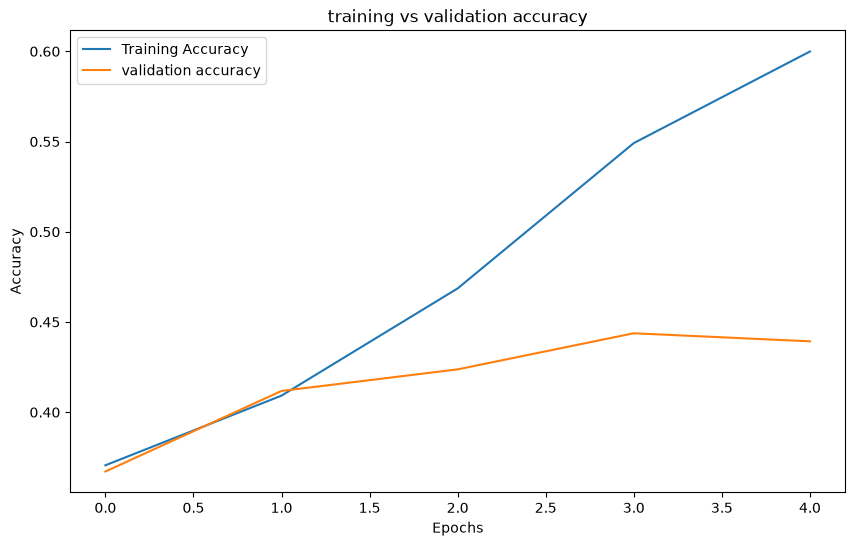

In [55]:
plt.figure(figsize = (10, 6))
plt.plot(history.history["accuracy"], label = "Training Accuracy")
plt.plot(history.history["val_accuracy"], label = "validation accuracy")
plt.title("training vs validation accuracy")
plt.xlabel("Epochs")
plt.ylabel("Accuracy")
plt.legend()
plt.show()

In [56]:
y_probability = model.predict(x_test)
y_pred = np.argmax(y_probability, axis=1)

375/375 ━━━━━━━━━━━━━━━━━━━━ 2s 5ms/step


In [57]:
cm = confusion_matrix(y_test,y_pred)

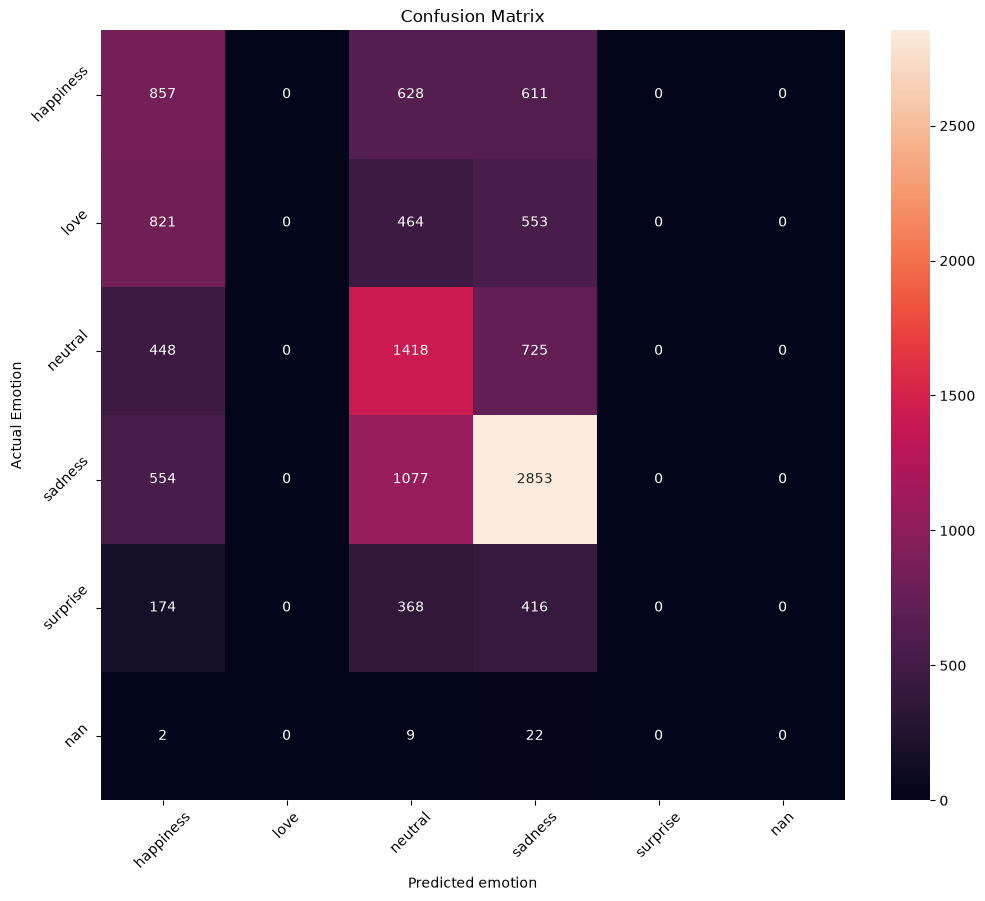

In [58]:
plt.figure(figsize = (12,10))
sns.heatmap(cm,annot=True, fmt="d",xticklabels=label_encoder.classes_, yticklabels = label_encoder.classes_)
plt.title("Confusion Matrix")
plt.xlabel("Predicted emotion")
plt.ylabel("Actual Emotion")
plt.xticks(rotation = 45)
plt.yticks(rotation = 45)
plt.show()

In [5]:
## GRU
from tensorflow.keras.layers import GRU

In [ ]:
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Embedding, GRU, Dropout, Dense

gru_model = Sequential()
gru_model.add(Embedding(input_dim=max_words, output_dim=128))
gru_model.add(GRU(128))
gru_model.add(Dropout(0.6))
gru_model.add(Dense(len(label_encoder.classes_), activation="softmax"))


In [ ]:
gru_model.compile(optimizer = "adam", loss = "sparse_categorical_crossentropy", metrics = ["accuracy"])

In [ ]:
gru_history = gru_model.fit(
    x_train, y_train, 
    validation_data = (x_val,y_val),
    epochs = 20,
    batch_size = 128
)

In [ ]:
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Embedding, LSTM, Bidirectional, Dropout, Dense

bilstm_model = Sequential()
bilstm_model.add(Embedding(input_dim=max_words, output_dim=128))
bilstm_model.add(Bidirectional(LSTM(128)))
bilstm_model.add(Dropout(0.5))
bilstm_model.add(Dense(len(label_encoder.classes_), activation="softmax"))


In [ ]:
bilstm_model.compile(optimizer = "adam",
                 loss = "sparse_categorical_crossentropy", metrics = ["accuracy"])

In [ ]:
bilstm_history = bilstm_model.fit(
    x_train, y_train, 
    validation_data = (x_val,y_val),
    epochs = 20,
    batch_size = 128
)
